# Lineage gene and peak dynamics

Set **`GENE`** below to look up its candidate peaks from your peak–gene table. Plot expression and peak accessibility **on the same coordinate system**, or separately, with **observed snapshot means optional**. Each RNA/ATAC temporal profile is standardized separately as a z-score to compare relative changes. The readout finds distance-weighted kNN in the corresponding RNA and ATAC model spaces along each continuous path. It estimates molecular features from real observed neighbors; it does not track the same measured cells over time.

The requested lineage is **E8.0 NMP → E8.75 Somitic mesoderm**. The saved 1,000-step example selects **0 accepted Somitic paths**, so its curves remain **NMP-origin diagnostics**. An empty lineage is never replaced by all paths. Use your own matching, validated `MODEL_DIR` for accepted lineage curves.

Run [the gastrulation dynamics tutorial](07_dynamics.ipynb) first, using its saved model directory. This notebook also reads the existing processed molecular H5AD files, read-only; the reduced benchmark files do not contain expression or peak columns. Install `.[notebooks,visualization]`.

In [1]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
import coati as ct
from coati import downstream as ds

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LATENT_DIR = Path(os.environ.get("COATI_GASTRULATION_DATA", project_dir.parent / "TraInfBench/data/processed/gastrulation"))
RAW_DIR = Path(os.environ.get("COATI_GASTRULATION_FEATURES", project_dir.parent / "TraInf/TraInf/Gastrulation/data"))
MODEL_DIR = Path(os.environ.get("COATI_GASTRULATION_RESULT", project_dir / "outputs/gastrulation-dynamics"))
# Change the gene name; peak IDs are resolved automatically from annotations.
GENE = "Tbx6"
PEAK_REGION = "promoter"  # None includes all candidate regions in the table.
MAX_PEAKS = 2             # None includes all eligible candidate peaks.
PLOT_LAYOUT = "combined" # RNA and all peaks on one axis; "separate" uses separate figures.
NORMALIZATION = "zscore" # Standardize each temporal profile independently.
SHOW_IQR = False         # Optional across-path spread, in the same standardized units.
SHOW_OBSERVED = False     # Optional measured snapshot-cohort means.

## Verify inputs and start from NMP

Use the **same prepared RNA50 and ATAC14 units** as the saved model. `start_time=1.` supplies a later starting cohort explicitly; it does not move E7.5 cells to E8.0. `predict_trajectory` otherwise retains its original default start and integration behavior.

In [2]:
rna = ad.read_h5ad(LATENT_DIR / "rna.h5ad")
atac = ad.read_h5ad(LATENT_DIR / "atac.h5ad")
assert rna.obs_names.is_unique and rna.obs_names.equals(atac.obs_names)
cells = ct.prepare_anndata(
    rna, use_rep="X_latent", time_key="time_point_processed",
    celltype=rna.obs["celltype"].astype(object).fillna("unknown"),
    secondary=atac.obsm["X_latent"], secondary_key="X_atac", warn=False,
)
result = ct.load_result(MODEL_DIR)
for i, time in enumerate(result.data.times):
    mask = np.isclose(cells.obs["time"], time)
    np.testing.assert_array_equal(result.data.primary[i], cells.obsm["X_latent"][mask])
    np.testing.assert_array_equal(result.data.secondary[i], cells.obsm["X_atac"][mask])
initial_mask = (cells.obs["stage"] == "E8.0") & (cells.obs["celltype"] == "NMP")
trajectory = result.predict_trajectory(
    cells.obsm["X_latent"][initial_mask], start_time=1., times=np.linspace(1., 2.5, 16),
)
trajectory["secondary"] = result.project_secondary(trajectory)
initial_barcodes = cells.obs_names[initial_mask].to_numpy(dtype=str)
print("NMP starting cells:", len(initial_barcodes), "Start / end time:", trajectory["times"][[0, -1]])

NMP starting cells: 237 Start / end time: [1.  2.5]


## Select the terminal lineage before molecular interpretation

`select_lineage` compares endpoints to real E8.75 RNA cells, using distance-weighted neighbors. A target vote of at least 0.6 and an empirical neighborhood support check are required. Every assignment and distance is returned, including rejected paths. An empty selection remains empty; changing labels or thresholds to produce a desired curve would not validate a fate.

In [3]:
lineage = ds.select_lineage(
    trajectory, cells, terminal_celltypes="Somitic mesoderm",
    use_rep="X_latent", n_neighbors=15, min_probability=.6,
)
lineage.assignments.insert(1, "initial_barcode", initial_barcodes)
print("Accepted NMP → Somitic paths:", len(lineage.indices), "/", len(initial_barcodes))
print("Empirical terminal support distance:", lineage.support_cutoff)
lineage.assignments.groupby("assigned_celltype").agg(paths=("path", "size"), selected=("selected", "sum"))

Accepted NMP → Somitic paths: 0 / 237
Empirical terminal support distance: 0.7834917716195413


,paths,selected
assigned_celltype,,
NMP,203,0
Spinal cord,33,0
unknown,1,0


## One gene name, candidate peaks from annotations

`find_gene_peaks` reads an existing DataFrame or CSV link table, matches the exact gene name, and optionally filters `region_type`. It orders candidates by absolute TSS distance, then removes duplicate peak IDs; `max_peaks` limits the display. Neither reconstructed curves nor readout scores determine selection.

Here `GENE="Tbx6"` chooses the two nearest promoter candidates from `nmp_peak_gene_links.csv`. These links are candidate annotations, not proof of regulation. Missing genes or eligible peaks raise a clear error instead of generating links.

`read_h5ad_features` streams only the selected columns and aligns cells by barcode. RNA `X` contains source log-normalized expression; no extra normalization is applied. ATAC `X` contains nonnegative counts: `binary=True` converts observed counts to presence/absence before fitting local peak-open probabilities.

In [4]:
links = ds.find_gene_peaks(
    GENE, RAW_DIR / "nmp_peak_gene_links.csv",
    region_type=PEAK_REGION, max_peaks=MAX_PEAKS,
)
genes, peaks = [GENE], links["peak"].tolist()

cache_path = project_dir / "outputs/lineage-nmp-features/observed_features.npz"
signature_path = cache_path.with_name("source_signature.json")
source_signature = {str((RAW_DIR / name).resolve()): {"size": (RAW_DIR / name).stat().st_size,
                    "mtime_ns": (RAW_DIR / name).stat().st_mtime_ns}
                    for name in ["gastrulation_rna_processed.h5ad", "gastrulation_atac_processed.h5ad"]}
gene_values = peak_values = None
if cache_path.exists() and signature_path.exists() and json.loads(signature_path.read_text()) == source_signature:
    # Reuse only named columns present in this source-verified local cache.
    with np.load(cache_path, allow_pickle=False) as cached:
        np.testing.assert_array_equal(cached["barcodes"], cells.obs_names.to_numpy(dtype=str))
        if set(genes) <= set(cached["genes"]) and set(peaks) <= set(cached["peaks"]):
            gene_columns = [list(cached["genes"]).index(name) for name in genes]
            peak_columns = [list(cached["peaks"]).index(name) for name in peaks]
            gene_values = cached["rna"][:, gene_columns].copy()
            peak_values = cached["atac"][:, peak_columns].copy()
if gene_values is None:
    gene_source = ds.read_h5ad_features(RAW_DIR / "gastrulation_rna_processed.h5ad", genes, obs_names=cells.obs_names)
    peak_source = ds.read_h5ad_features(RAW_DIR / "gastrulation_atac_processed.h5ad", peaks, obs_names=cells.obs_names, binary=True)
    np.testing.assert_array_equal(gene_source.barcodes, peak_source.barcodes)
    gene_values, peak_values = gene_source.values, peak_source.values
print("Observed genes / peaks:", gene_values.shape, peak_values.shape)
links[["gene", "peak", "region_type", "distance"]]

Observed genes / peaks: (35503, 1) (35503, 2)


,gene,peak,region_type,distance
0,Tbx6,chr7:126785067-126785667,promoter,181
1,Tbx6,chr7:126785767-126786367,promoter,519


## Fit and test local molecular readouts

PCA/LSI trajectories do not directly contain gene/peak values. Fit separate 30-neighbor decoders in RNA50 and ATAC14, using aligned observed molecular features. The decoder interpolates local observations; it does not invert PCA/LSI.

Reserve 20% of cells per stage for an independent readout check. `validate` scores all test cells against the frozen training-mean baseline and reports neighborhood support separately. For binary peaks, MSE is a **Brier score**; a skill score at or below zero fails to improve the constant observed training open fraction. A supported latent coordinate alone does not establish accurate molecular decoding.

The source PCA/LSI and scales remain fixed and may use the full atlas. This holds observations out of decoder fitting, not preprocessing or vector-field training.

In [5]:
rng = np.random.default_rng(17)
train_rows, test_rows = [], []
for time in np.unique(cells.obs["time"]):
    rows = rng.permutation(np.flatnonzero(cells.obs["time"].to_numpy() == time))
    split = round(.2 * len(rows))
    train_rows.extend(rows[split:])
    test_rows.extend(rows[:split])
train_rows, test_rows = np.array(train_rows), np.array(test_rows)
assert not np.intersect1d(train_rows, test_rows).size
rna_decoder = ds.fit_feature_decoder(
    cells.obsm["X_latent"][train_rows], gene_values[train_rows], features=genes,
    units="Source log-normalized expression",
)
atac_decoder = ds.fit_feature_decoder(
    cells.obsm["X_atac"][train_rows], peak_values[train_rows], features=peaks,
    binary=True, units="Local peak-open probability",
)
gene_quality = rna_decoder.validate(cells.obsm["X_latent"][test_rows], gene_values[test_rows])
peak_quality = atac_decoder.validate(cells.obsm["X_atac"][test_rows], peak_values[test_rows])
gene_quality = gene_quality.rename(columns={"MSE": "squared_error"})
peak_quality = peak_quality.rename(columns={"Brier": "squared_error"})
gene_quality["error_type"], peak_quality["error_type"] = "MSE", "Brier"
gene_quality.insert(0, "modality", "RNA")
peak_quality.insert(0, "modality", "ATAC")
quality = pd.concat([gene_quality, peak_quality], ignore_index=True)
quality.round(4)

,modality,feature,test_cells,RMSE,baseline_RMSE,squared_error,skill_vs_training_mean,support_coverage,error_type
0,RNA,Tbx6,7101,0.1755,0.2155,0.0308,0.3368,0.9882,MSE
1,ATAC,chr7:126785067-126785667,7101,0.2707,0.3079,0.0733,0.2273,0.9907,Brier
2,ATAC,chr7:126785767-126786367,7101,0.1876,0.1871,0.0352,-0.0050,0.9907,Brier


## Summarize only accepted lineage paths

`compute_gene_peak_dynamics` reads the gene and its candidate peaks along the same selected paths. Unbalanced models use normalized growth weights within supported paths at each time; balanced models use uniform weights.

For display, each temporal mean profile is standardized independently:

$$z_f(t)=\frac{m_f(t)-\mathrm{mean}_t[m_f]}{\mathrm{std}_t[m_f]}.$$

This follows the paper's separately standardized RNA and ATAC profiles. The plotted z-scores describe relative changes; the stored readouts retain their original units. No extra log transformation is added to the source log-normalized RNA or binary-peak readouts.

Observed reference points are optional. Below we choose E8.0 NMP and later Somitic annotation cohorts explicitly. Their means use each corresponding trajectory profile's center and scale, keeping both on the same standardized coordinate system. These snapshots contain different cells.

In [6]:
reference_times = [1., 2., 2.5]
reference_types = ["NMP", "Somitic mesoderm", "Somitic mesoderm"]
observed_rows = []
for time, celltype in zip(reference_times, reference_types):
    mask = np.isclose(cells.obs["time"], time) & (cells.obs["celltype"] == celltype)
    if not mask.any():
        continue
    for modality, names, values in [("RNA", genes, gene_values), ("ATAC", peaks, peak_values)]:
        for j, feature in enumerate(names):
            observed_rows.append(dict(modality=modality, feature=feature, time=time,
                                      mean=float(values[mask, j].mean()), n_cells=int(mask.sum()), cohort=celltype))
observed_summary = pd.DataFrame(observed_rows)
weighting = "growth" if "log_weights" in trajectory else "uniform"
if len(lineage.indices):
    lineage_pair = ds.compute_gene_peak_dynamics(
        GENE, trajectory, gene_decoder=rna_decoder, peak_decoder=atac_decoder,
        peak_gene_links=links, selection=lineage, weighting=weighting,
    )
    lineage_pair.plot(layout=PLOT_LAYOUT, normalization=NORMALIZATION,
                      show_observed=SHOW_OBSERVED, observed=observed_summary, show_iqr=SHOW_IQR)
    plt.show()
else:
    print("No accepted NMP → Somitic lineage in this checkpoint. No lineage-specific molecular curves are reported.")

No accepted NMP → Somitic lineage in this checkpoint. No lineage-specific molecular curves are reported.


## Diagnostic: RNA and peaks on one coordinate system

The blue gene curve and colored dashed peak curves share **one time axis and one z-score axis**. Each curve is centered and scaled using its own temporal mean profile. The 237 NMP-origin paths here **are not a validated NMP → Somitic lineage**.

A star marks a peak readout that did not improve the held-out baseline. Standardizing a weak readout does not validate it. `SHOW_IQR` optionally adds across-path spread using the same transform; it is not a molecular confidence interval.

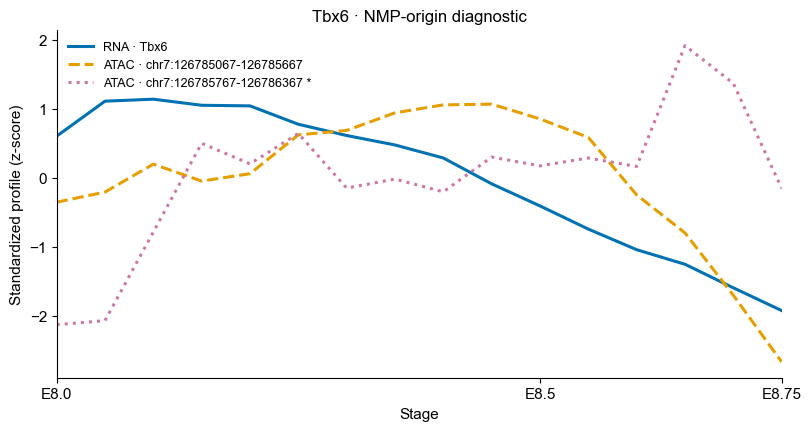

In [7]:
diagnostic_pair = ds.compute_gene_peak_dynamics(
    GENE, trajectory, gene_decoder=rna_decoder, peak_decoder=atac_decoder,
    peak_gene_links=links, weighting=weighting,
)

def format_plot(axes_by_modality):
    unique_axes = list(dict.fromkeys([*axes_by_modality["gene"], *axes_by_modality["peaks"]]))
    for ax in unique_axes:
        ax.set_xticks(reference_times, ["E8.0", "E8.5", "E8.75"])
        ax.set_xlabel("Stage")
    for peak, ax in zip(diagnostic_pair.atac.features, axes_by_modality["peaks"]):
        if peak_quality.set_index("feature").loc[peak, "skill_vs_training_mean"] <= 0:
            for line in ax.lines:
                if line.get_label().startswith(f"ATAC · {peak}"):
                    line.set_label(line.get_label() + " *")
    for ax in unique_axes:
        ax.legend(frameon=False, fontsize=9, loc="best")
    for figure in dict.fromkeys(ax.figure for ax in unique_axes):
        if len(figure.axes) == 1:
            figure.axes[0].set_title(f"{GENE} · NMP-origin diagnostic", fontsize=12)
        else:
            figure.suptitle(f"{GENE} · NMP-origin diagnostic", fontsize=12)
    plt.show()

axes = diagnostic_pair.plot(layout=PLOT_LAYOUT, normalization=NORMALIZATION,
                            show_observed=SHOW_OBSERVED, observed=observed_summary, show_iqr=SHOW_IQR)
format_plot(axes)

## Plot separately or add observed snapshots

`layout="separate"` uses separate gene and peak figures, with the same independent z-score normalization. `show_observed=False` keeps the focus on the reconstructed profiles; enabling it adds the supplied snapshot-cohort means on each curve's standardized scale.

```python
# Optional observed points on the common coordinate system:
diagnostic_pair.plot(layout="combined", normalization="zscore",
                     show_observed=True, observed=observed_summary)
```

The normalization affects the display only. It does not refit readouts, alter paths or establish temporal precedence. Unsupported times leave gaps; constant mean profiles are flat at zero, with undefined normalized IQR/observed overlays omitted.

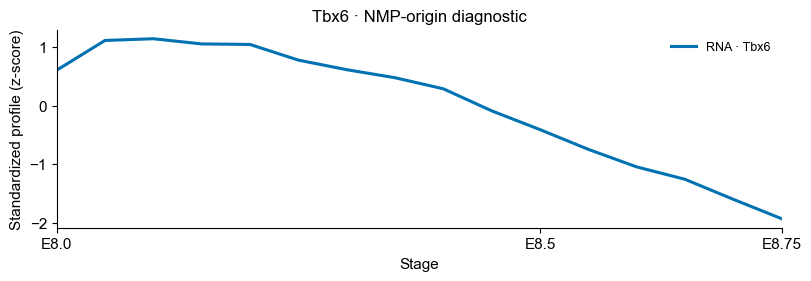

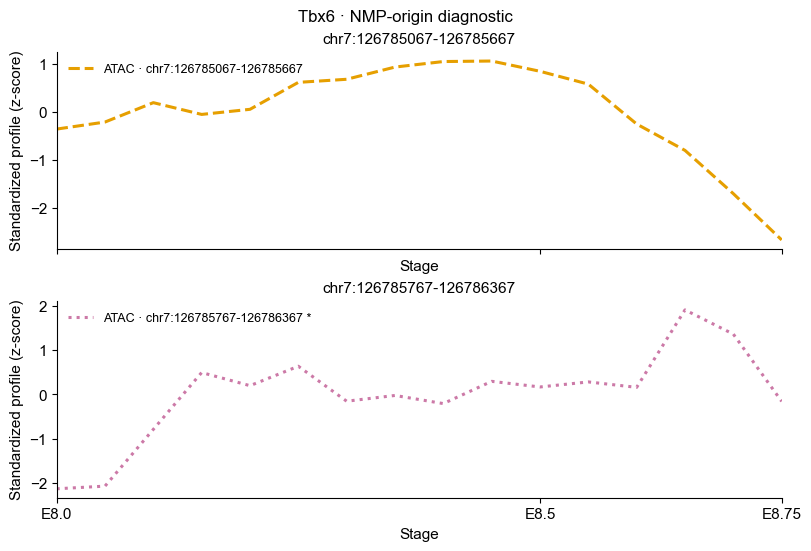

In [8]:
axes = diagnostic_pair.plot(layout="separate", normalization=NORMALIZATION,
                            show_observed=SHOW_OBSERVED, observed=observed_summary, show_iqr=SHOW_IQR)
format_plot(axes)